# 보스턴 집값 — 회귀 모델 고도화 · 검증 및 평가 종합 실습

수업 필기 `회귀 모델 성능 고도화 실습` 을 **실행 가능하도록 정리 · 개선한 노트**입니다.
(교재 `머신러닝` v7 p.141 · p.142~145 — GridSearchCV · RandomizedSearchCV 회귀 실습, `모델검증및평가` 18장 — RMSE · 회귀 종합 실습)

- 회귀 트리 · 랜덤 포레스트는 [Day 024](../../2026-10-13/), 회귀 `GridSearchCV` 는 [Day 028](../../2026-10-19/) 에서 처음 했습니다.
- 원본에서 고친 부분은 **📝 고친 부분** 으로 따로 적어 두었습니다.

> 데이터 : `house_price.csv` (보스턴 506곳 × 14열, 정답 `medv` = 집값 중앙값, 단위 천 달러)

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('./house_price.csv')
X_data = df.drop(columns=['medv'])     # 특성 13개
y_data = df['medv']                    # 정답 : 집값

X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.25, random_state=0)
print("학습용 :", X_train.shape, " 평가용 :", X_test.shape)
print("X · y 인덱스 짝 :", (X_train.index == y_train.index).all())

학습용 : (379, 13)  평가용 : (127, 13)
X · y 인덱스 짝 : True


> **📝 고친 부분** — 경로 `C:/Users/playdata2/work/house_price.csv` → `./house_price.csv`, `display(X_data)` · `print(y_data)` 전체 출력 → 모양만, 인덱스 확인은 한 줄로

## 1. 회귀 평가 지표 — RMSE (교재 `모델검증및평가`)

| 지표 | 계산 | 단위 |
|---|---|---|
| **MSE** (평균 제곱 오차) | (예측 − 정답)² 의 **평균** | 집값² (천 달러²) — 해석이 어렵다 |
| **RMSE** (평균 제곱근 오차) | **√MSE** | 집값과 **같은 단위** (천 달러) |

제곱하기 때문에 **크게 틀린 예측**에 벌점이 몰린다(오차 10 은 오차 1 의 100배).

![RMSE 애니메이션](./images/anim_03_rmse_squares.gif)

🎬 평가용 집 20곳의 오차(세로선)를 하나씩 **정사각형(오차²)** 으로 바꿔 쌓는다. 사각형 넓이의 평균이 MSE, 그 한 변의 길이가 RMSE. 큰 사각형 몇 개가 RMSE 를 끌어올린다 — 실제 집값 **50**(이 데이터의 상한값)인 집을 20 으로 예측한 오차 하나(약 30)가 혼자 20곳 MSE 의 **약 80%** 를 차지한다.

## 2. 결정 트리 회귀 고도화 — `GridSearchCV` (필기)

In [3]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, root_mean_squared_error

params = {
    'max_depth': range(3, 21),          # 3 ~ 20 → 18개
    'min_samples_leaf': [2, 3, 4, 5],   # 4개 → 18 × 4 = 72가지, 5-fold 360번 학습
}
grid_dt = GridSearchCV(DecisionTreeRegressor(random_state=0), param_grid=params,
                       scoring='neg_root_mean_squared_error', cv=5)
grid_dt.fit(X_train, y_train)

best_dt = grid_dt.best_estimator_
print("best :", grid_dt.best_params_)
print("검증 RMSE :", round(-grid_dt.best_score_, 3), " ← best_score_ 는 음수(-RMSE)라 부호를 뒤집어 읽는다")

pred_dt = best_dt.predict(X_test)
mse = mean_squared_error(y_test, pred_dt)
print(f"평가용 MSE : {mse:.3f}  →  RMSE = √MSE = {np.sqrt(mse):.3f}  (root_mean_squared_error : {root_mean_squared_error(y_test, pred_dt):.3f})")
print(f"학습용 RMSE : {root_mean_squared_error(y_train, best_dt.predict(X_train)):.3f}")

best : {'max_depth': 8, 'min_samples_leaf': 5}
검증 RMSE : 3.855  ← best_score_ 는 음수(-RMSE)라 부호를 뒤집어 읽는다
평가용 MSE : 29.143  →  RMSE = √MSE = 5.398  (root_mean_squared_error : 5.398)
학습용 RMSE : 2.636


검증 3.85 vs 평가 **5.40** — [Day 028](../../2026-10-19/) 에서 본 것처럼 평가용 127곳 한 번의 결과는 흔들림이 크다(분할을 20번 바꾸면 튜닝이 평균 4.82 → 4.64 로 좋아졌다).

> **📝 고친 부분**
> - `print(grid_dt.best_score_)` 의 **−3.85** 를 그대로 두면 "RMSE 가 음수?" 로 헷갈린다 → `-grid_dt.best_score_` 로 출력. `GridSearchCV` 는 클수록 좋은 점수를 고르기 때문에 RMSE 에 − 를 붙인 `neg_` 를 쓴다.
> - `print("검증 완료")` → `fit` 이 끝나면 탐색 + 교차 검증 + best 조합으로 **재학습(refit)** 까지 끝난 상태
> - 평가용 예측값 127개와 정답 전체를 `print` → RMSE 하나로 요약

### 2-1. 같은 탐색을 `RandomizedSearchCV` 로 (교재 p.143 사용법)

`param_distributions` 에 `range` 를 그대로 주고, 그중 `n_iter` 개만 무작위로 뽑는다.

In [4]:
from sklearn.model_selection import RandomizedSearchCV

random_dt = RandomizedSearchCV(
    DecisionTreeRegressor(random_state=0),
    param_distributions={'max_depth': range(3, 21), 'min_samples_leaf': range(2, 11)},   # 18 × 9 = 162가지
    n_iter=20,                          # 그중 20개만
    scoring='neg_root_mean_squared_error', cv=5, random_state=0)
random_dt.fit(X_train, y_train)
print("best :", random_dt.best_params_, " 검증 RMSE :", round(-random_dt.best_score_, 3),
      " 평가 RMSE :", round(root_mean_squared_error(y_test, random_dt.predict(X_test)), 3))

best : {'min_samples_leaf': 5, 'max_depth': 10}  검증 RMSE : 3.859  평가 RMSE : 5.414


162가지 중 **20개만** 봤는데 검증 RMSE 3.86 — 72가지를 전부 본 `GridSearchCV`(3.85)와 거의 같다. 고른 조합은 달라도(`max_depth=10` vs 8) 성능 차이는 작다 → 후보가 많을 때는 `RandomizedSearchCV` 로 시간을 아낀다([Day 029](../../2026-10-20/) 에서 분류로 확인한 것과 같은 결론).

## 3. 랜덤 포레스트 회귀 고도화 — `RandomizedSearchCV` (필기)

In [5]:
from sklearn.ensemble import RandomForestRegressor

params_rf = {
    'n_estimators': [100, 200, 300, 400, 500],   # 5
    'max_depth': range(3, 31),                   # 28
    'min_samples_leaf': [2, 3, 4, 5],            # 4 → 5 × 28 × 4 = 560가지
}
random_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=0),
    param_distributions=params_rf,
    n_iter=120,                                  # 560가지 중 120개 (21%) × 5-fold = 600번 학습
    scoring='neg_root_mean_squared_error', cv=5, random_state=0,
    n_jobs=-1)                                   # CPU 코어 모두 사용 (수업 필기에는 없음, 결과는 같다)
random_rf.fit(X_train, y_train)

best_rf = random_rf.best_estimator_
print("best :", random_rf.best_params_)
print("검증 RMSE :", round(-random_rf.best_score_, 3))
print("평가 RMSE :", round(root_mean_squared_error(y_test, best_rf.predict(X_test)), 3))

best : {'n_estimators': 100, 'min_samples_leaf': 2, 'max_depth': 10}
검증 RMSE : 3.489
평가 RMSE : 4.305


In [6]:
# 비교 : 아무것도 안 바꾼 기본값 랜덤 포레스트 (Day 024)
from sklearn.model_selection import cross_val_score

rf0 = RandomForestRegressor(random_state=0)
cv_rf0 = -cross_val_score(rf0, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error').mean()
rf0.fit(X_train, y_train)
print("기본값 :", {k: rf0.get_params()[k] for k in ['n_estimators', 'max_depth', 'min_samples_leaf']})
print("검증 RMSE :", round(cv_rf0, 3), " 평가 RMSE :", round(root_mean_squared_error(y_test, rf0.predict(X_test)), 3))

기본값 : {'n_estimators': 100, 'max_depth': None, 'min_samples_leaf': 1}
검증 RMSE : 3.463  평가 RMSE : 4.072


| 랜덤 포레스트 | 검증 RMSE (5-fold) | 평가 RMSE |
|---|---|---|
| 기본값 (`min_samples_leaf=1`) | **3.463** | **4.072** |
| `RandomizedSearchCV` best (`max_depth=10, min_samples_leaf=2`) | 3.489 | 4.305 |

**튜닝했더니 검증 점수부터 기본값보다 나쁘다.** 탐색 범위 `min_samples_leaf: [2, 3, 4, 5]` 에 **기본값 1 이 빠져 있었기** 때문 — 이 데이터에서는 리프를 1개까지 허용하는 게 가장 좋았는데(랜덤 포레스트는 트리 여러 개를 평균 내서 과대적합을 줄이므로 리프가 작아도 괜찮다), 후보에 없으니 고를 수가 없었다.

→ **탐색 범위에는 기본값을 꼭 포함**하고, 튜닝 결과는 기본값 모델과 **같은 교차 검증으로** 비교한다.

> **📝 고친 부분**
> - `max_depth: range(3, 31)` — 학습용 379곳으로 자란 트리는 깊이 20 안팎에서 멈추므로 20 이상은 **같은 모델**이다(검증 RMSE 가 소수 셋째 자리까지 같은 후보가 여러 개). 후보 560개 중 상당수가 중복.
> - 주석 "검증용 데이터에 대한 최적의 성능(-RMSE)" → 정확히는 **5개 검증 fold 의 평균** −RMSE

### 3-1. 개선 : 기본값을 포함한 탐색 범위

In [7]:
params_rf2 = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 15, 20],          # None = 끝까지 (기본값)
    'min_samples_leaf': [1, 2, 3, 5],            # 1 = 기본값
    'max_features': [1.0, 0.5, 0.33],            # 분할마다 볼 특성 비율 (1.0 = 기본값, 0.33 ≈ 특성 13개 중 4개)
}
random_rf2 = RandomizedSearchCV(RandomForestRegressor(random_state=0), params_rf2, n_iter=40,
                                scoring='neg_root_mean_squared_error', cv=5, random_state=0, n_jobs=-1)
random_rf2.fit(X_train, y_train)
print("best :", random_rf2.best_params_)
print("검증 RMSE :", round(-random_rf2.best_score_, 3),
      " 평가 RMSE :", round(root_mean_squared_error(y_test, random_rf2.predict(X_test)), 3))

r2 = pd.DataFrame(random_rf2.cv_results_)
print("max_features 별 최고 검증 RMSE :", (-r2.groupby('param_max_features')['mean_test_score'].max()).round(3).to_dict())
print("min_samples_leaf 별 최고 검증 RMSE :", (-r2.groupby('param_min_samples_leaf')['mean_test_score'].max()).round(3).to_dict())

best : {'n_estimators': 300, 'min_samples_leaf': 1, 'max_features': 0.33, 'max_depth': None}
검증 RMSE : 3.162  평가 RMSE : 4.567
max_features 별 최고 검증 RMSE : {0.33: 3.162, 0.5: 3.192, 1.0: 3.463}
min_samples_leaf 별 최고 검증 RMSE : {1: 3.162, 2: 3.275, 3: 3.348, 5: 3.484}


검증 RMSE 는 3.46 → **3.16** 으로 좋아졌는데 평가 RMSE 는 4.07 → 4.57 로 **나빠졌다**. 어느 쪽을 믿어야 할까?
평가용 127곳 **한 번**의 결과 vs 학습용 안의 5-fold 평균 — 둘 다 표본이 작다. 그래서 **전체 506곳으로 5-fold 를 3번 반복**(15번 평가)해서 세 모델을 비교했다.

In [8]:
from sklearn.model_selection import RepeatedKFold

rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=0)
models = {
    '기본값': RandomForestRegressor(random_state=0, n_jobs=-1),
    '필기 best (leaf 2~5 에서)': RandomForestRegressor(random_state=0, n_jobs=-1, **random_rf.best_params_),
    '개선 best (기본값 포함)': RandomForestRegressor(random_state=0, n_jobs=-1, **random_rf2.best_params_),
}
rows = {}
for name, m in models.items():
    s = -cross_val_score(m, X_data, y_data, cv=rkf, scoring='neg_root_mean_squared_error')
    rows[name] = {'평균 RMSE (15번)': s.mean(), '표준편차': s.std()}
pd.DataFrame(rows).T.round(3)

,평균 RMSE (15번),표준편차
기본값,3.439,0.760
필기 best (leaf 2~5 에서),3.546,0.795
개선 best (기본값 포함),3.264,0.762


| 랜덤 포레스트 | 반복 교차 검증 (15번 평균) | 평가용 한 번 |
|---|---|---|
| 기본값 | 3.44 | **4.07** |
| 필기 best | 3.55 (가장 나쁨) | 4.31 |
| 개선 best (`max_features=0.33`, `leaf=1`) | **3.26** | 4.57 |

15번 평균으로는 **개선 best 가 가장 좋고**, 평가용 한 번으로는 가장 나쁘다. 표준편차가 0.76 이나 돼서 평가용 127곳 하나로는 0.5 차이도 뒤집힌다 — 데이터가 작을 때는 **반복 교차 검증**으로 모델을 고르는 게 더 믿을 만하다.

![검증 vs 평가 애니메이션](./images/anim_04_cv_vs_test.gif)

🎬 필기의 `RandomizedSearchCV` 후보 120개를 하나씩 찍었다. 가로 = 검증 RMSE(5-fold), 세로 = 평가 RMSE. 대체로 같이 움직이지만(상관 0.75) **검증 1등이 평가 1등은 아니고**, 기본값(★)은 둘 다에서 후보들보다 왼쪽 아래에 있다 — 탐색 범위 밖에 더 좋은 답이 있었다.

## 4. 특성 중요도로 회귀 모델 검증 (교재 `모델검증및평가`)

In [9]:
from sklearn.inspection import permutation_importance

builtin = pd.Series(best_rf.feature_importances_, index=X_train.columns)
perm = permutation_importance(best_rf, X_test, y_test, n_repeats=10, random_state=0,
                              scoring='neg_root_mean_squared_error')
perm = pd.Series(perm.importances_mean, index=X_test.columns)   # 섞었을 때 RMSE 가 얼마나 늘었나

check = pd.DataFrame({'내장(학습용)': builtin, '순열(평가용, RMSE 증가)': perm}).sort_values('내장(학습용)', ascending=False)
check['내장 순위'] = range(1, len(check) + 1)
check['순열 순위'] = perm.rank(ascending=False)[check.index].astype(int)
check.round(3).head(8)

,내장(학습용),"순열(평가용, RMSE 증가)",내장 순위,순열 순위
rm,0.422,2.798,1,2
lstat,0.418,3.093,2,1
dis,0.039,0.492,3,3
crim,0.037,0.224,4,4
ptratio,0.020,0.181,5,5
tax,0.015,0.051,6,7
nox,0.014,0.146,7,6
age,0.012,0.016,8,9


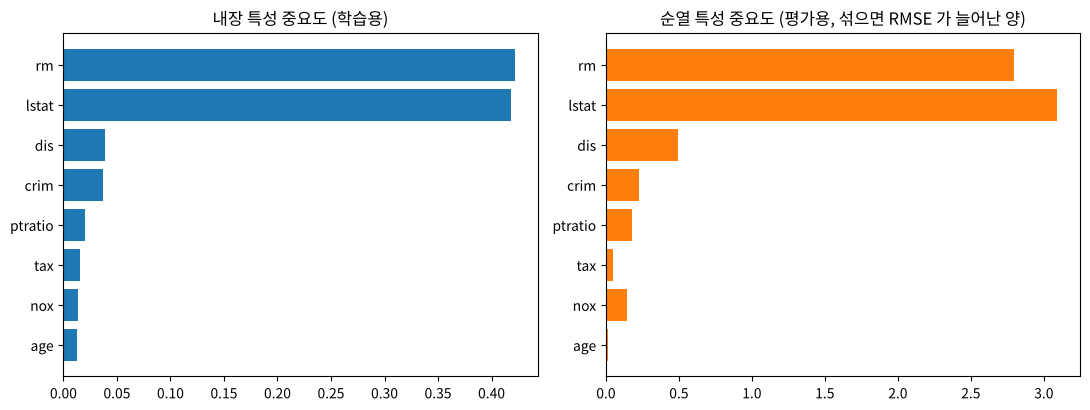

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
top = check.head(8).index[::-1]
axes[0].barh(top, check.loc[top, '내장(학습용)'])
axes[0].set_title('내장 특성 중요도 (학습용)')
axes[1].barh(top, check.loc[top, '순열(평가용, RMSE 증가)'], color='tab:orange')
axes[1].set_title('순열 특성 중요도 (평가용, 섞으면 RMSE 가 늘어난 양)')
plt.tight_layout()
plt.show()

- 내장 1 · 2위 **`rm`(방 개수) · `lstat`(저소득층 비율)** 이 순열에서도 1 · 2위 — `lstat` 을 섞으면 평가 RMSE 가 **3.1** 이나 늘어난다. 상위권 순위가 유지되므로 교재 기준 **"안정적으로 검증된 모델"**.
- 이 두 특성은 [Day 021](../../2026-10-07/) 선형 회귀 · [Day 024](../../2026-10-13/) 회귀 트리에서도 맨 위였다.

## 5. 정리

| 보스턴 집값 (평가용 127곳) | 검증 RMSE | 평가 RMSE |
|---|---|---|
| 결정 트리 `GridSearchCV` (72가지) | 3.85 | 5.40 |
| 랜덤 포레스트 기본값 | 3.46 | **4.07** |
| 랜덤 포레스트 `RandomizedSearchCV` (필기, 120/560) | 3.49 | 4.31 |
| 랜덤 포레스트 `RandomizedSearchCV` (기본값 포함, 40개) | **3.16** | 4.57 |

1. 탐색 범위에 **기본값을 포함**하자 — 없으면 튜닝이 오히려 손해일 수 있다.
2. 튜닝 결과는 **같은 교차 검증**으로 기본값과 비교하자 — 평가용 한 번만 보면 작은 데이터에서는 판단이 뒤집힌다.
3. 고른 모델은 **내장 vs 순열 특성 중요도**로 근거가 같은지 확인하자.